In [2]:
import pandas as pd
import numpy as np
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score


## Clustering

In [3]:
df = pd.read_pickle("./data_features_clustering")
df.columns

Index(['Unnamed: 0', 'id', 'connectionTime', 'disconnectTime',
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'siteID', 'spaceID',
       'stationID', 'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin', 'connected_total_min',
       'connection_hour', 'disconnect_hour', 'connection_hour_sin',
       'connection_hour_cos', 'disconnect_hour_sin', 'disconnect_hour_cos',
       'connection_isWeekday', 'isRegisteredUser'],
      dtype='object')

In [4]:
def scale_features(features:pd.DataFrame, scaler:StandardScaler):
    non_binary_cols = features.columns[features.nunique() > 2]
    scaled_features = features.copy()
    scaled_features[non_binary_cols] = scaler.fit_transform(features[non_binary_cols])
    return scaled_features

def plot_elbow_graph(features:pd.DataFrame, range:range):
    inertia = []
    K = range
    for k in K:
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(features)
        inertia.append(kmeans.inertia_)

    plt.figure(figsize=(8, 5))
    plt.plot(K, inertia, "bo-", markersize=8)
    plt.title("Elbow Plot for Optimal Number of Clusters")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()


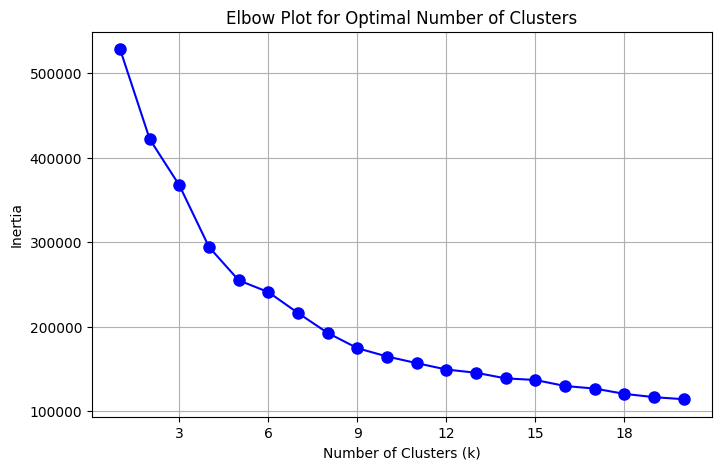

In [5]:
scaler = StandardScaler()
features = df.drop(columns=["Unnamed: 0", "id", "connectionTime", "disconnectTime", "doneChargingTime", "sessionID", "siteID", "spaceID",
                    "stationID", 'timezone', 'userID', 'userInputs', 'endChargingTime', 'connection_hour', 'disconnect_hour'])
scaled_features = scale_features(features, scaler)
plot_elbow_graph(scaled_features, range(1, 21))

In [6]:
optimal_k = 5  # Chosen based on the elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=69)
df['Cluster'] = kmeans.fit_predict(scaled_features)

In [9]:
# Run KMeans multiple times with different random states

def run_random_states(n:int, n_clusters:int, features:pd.DataFrame):
    sil_scores = []
    dbi_scores = []
    kmeans_models = []

    for i in range(n):
        kmeans = KMeans(n_clusters, random_state=i)  # Change the number of clusters if needed
        kmeans.fit(features)
        
        # Compute the Silhouette Score for the current model
        score = silhouette_score(features, kmeans.labels_)
        dbi = davies_bouldin_score(features, kmeans.labels_)
        sil_scores.append(score)
        dbi_scores.append(dbi)
        kmeans_models.append(kmeans)


    # Output the best silhouette score and its corresponding model
    print(f"Best Silhouette Score: {sil_scores[np.argmax(sil_scores)]}")
    print(f"Best DBI Score: {dbi_scores[np.argmin(dbi_scores)]}")

    return kmeans_models, sil_scores, dbi_scores


In [10]:
kmeans_models, sil_scores, dbi_scores = run_random_states(10,5,scaled_features)

Best Silhouette Score: 0.28990547750825046
Best DBI Score: 1.129592729890137


## Analyse

In [27]:
def evaluate_kmeans(kmeans:KMeans, features:pd.DataFrame):
    # Get number of entries

    cluster_labels = kmeans.labels_

    cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

    print("Number of entries in each cluster:")
    print(cluster_counts)

    # Silhouette Score
    silhouette = silhouette_score(features, kmeans.labels_)
    print(f"Silhouette Score: {silhouette}")

    # Davies-Bouldin Index
    dbi = davies_bouldin_score(features, kmeans.labels_)
    print(f"Davies-Bouldin Index: {dbi}")
    
evaluate_kmeans(kmeans, scaled_features)

Number of entries in each cluster:
0    15373
1    12725
2     6522
3    11750
4    17451
Name: count, dtype: int64
Silhouette Score: 0.2896584909289534
Davies-Bouldin Index: 1.1881939663899908


distance matrix between clusters:
[[0.         3.42212189 3.1394866  2.95704689 2.83647388]
 [3.42212189 0.         4.4706191  3.5764138  2.71573098]
 [3.1394866  4.4706191  0.         4.17251596 3.99736914]
 [2.95704689 3.5764138  4.17251596 0.         3.16801718]
 [2.83647388 2.71573098 3.99736914 3.16801718 0.        ]]


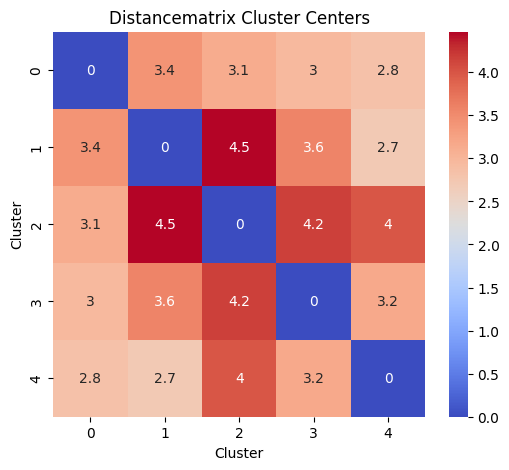

In [33]:
from sklearn.metrics import pairwise_distances

cluster_centers_scaled = kmeans.cluster_centers_

distances = pairwise_distances(cluster_centers_scaled, metric='euclidean')

print("distance matrix between clusters:")
print(distances)

plt.figure(figsize=(6, 5))
sns.heatmap(distances, annot=True, cmap='coolwarm', xticklabels=np.arange(0, len(distances)), yticklabels=np.arange(0, len(distances)))
plt.title('Distancematrix Cluster Centers')
plt.xlabel('Cluster')
plt.ylabel('Cluster')
plt.show()

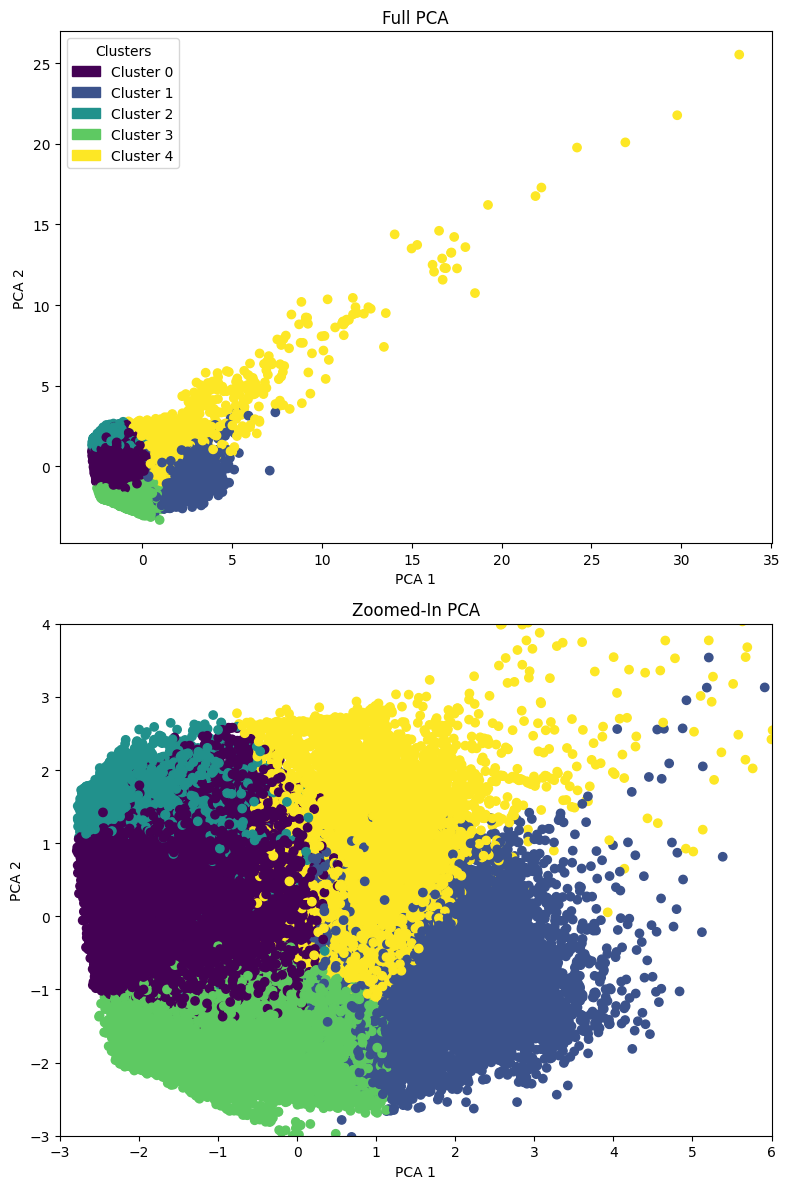

In [42]:
from sklearn.decomposition import PCA
import matplotlib.patches as mpatches

pca = PCA(n_components=2)
data_pca = pca.fit_transform(scaled_features)

# Create the figure with 2 subplots (1 row, 2 columns)
fig, ax = plt.subplots(2, 1, figsize=(8, 12))

# Create the legends
legend_labels = [f'Cluster {i}' for i in range(optimal_k)]  # 'Cluster 0', 'Cluster 1', ..., 'Cluster 4'
colors = [plt.cm.viridis(i / (optimal_k - 1)) for i in range(optimal_k)]  # Get colors for 5 clusters
patches = [mpatches.Patch(color=color, label=label) for color, label in zip(colors, legend_labels)]

# full plot
ax[0].scatter(data_pca[:, 0], data_pca[:, 1], c=df['Cluster'], cmap='viridis')
ax[0].set_xlabel('PCA 1')
ax[0].set_ylabel('PCA 2')
ax[0].set_title('Full PCA')
ax[0].legend(handles=patches, title="Clusters")

# zoomed in
ax[1].scatter(data_pca[:, 0], data_pca[:, 1], c=df['Cluster'], cmap='viridis')
ax[1].set_xlim(-3, 6) 
ax[1].set_ylim(-3, 4)
ax[1].set_xlabel('PCA 1')
ax[1].set_ylabel('PCA 2')
ax[1].set_title('Zoomed-In PCA')

plt.tight_layout()  
plt.show()

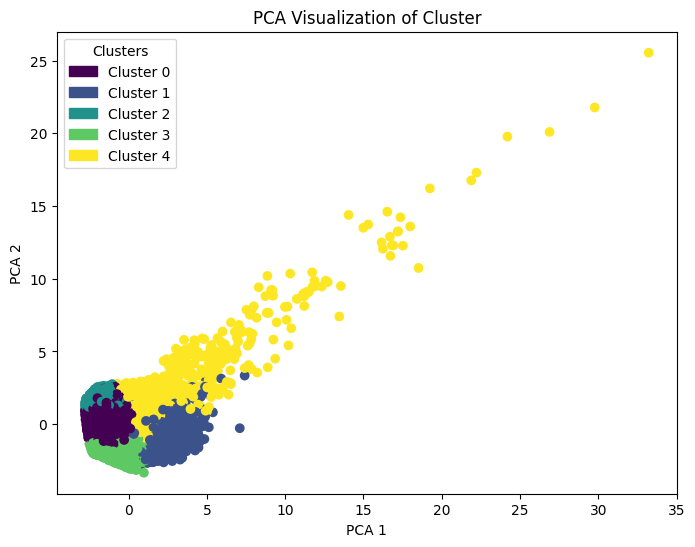

In [43]:
pca = PCA(n_components=2)
data_pca = pca.fit_transform(scaled_features)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(data_pca[:, 0], data_pca[:, 1], c=df['Cluster'], cmap='viridis')

legend_labels = [f'Cluster {i}' for i in range(optimal_k)] 
colors = [plt.cm.viridis(i / (optimal_k - 1)) for i in range(optimal_k)]
patches = [mpatches.Patch(color=color, label=label) for color, label in zip(colors, legend_labels)]

plt.legend(handles=patches, title="Clusters")
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('PCA Visualization of Cluster')
plt.show()

In [12]:
def decode_hour(sin_feature, cos_feature):
    # Decode the hour from the sin and cos components
    radians = np.arctan2(sin_feature, cos_feature)
    hour = (radians / (2 * np.pi)) * 24  # Convert to a 24-hour format
    
    # Ensure the hour is always positive and in the correct range [0, 24)
    hour = (hour + 24) % 24
    
    return hour

def plot_cluster_centers(kmeans:KMeans, features:pd.DataFrame):
    # Get Cluster Centers (in scaled space)
    cluster_centers_scaled = kmeans.cluster_centers_
    
    cluster_centers_original = pd.DataFrame(cluster_centers_scaled, columns=scaled_features.columns)

    # Replace the scaled columns with their inverse-transformed values
    non_binary_cols = features.columns[features.nunique() > 2]
    cluster_centers_original[non_binary_cols] = scaler.inverse_transform(cluster_centers_scaled[:, :len(non_binary_cols)])

    # Decode the connection_hour and disconnect_hour
    cluster_centers_original["connection_hour"] = decode_hour(
        cluster_centers_original["connection_hour_sin"], cluster_centers_original["connection_hour_cos"]
    )
    cluster_centers_original["disconnect_hour"] = decode_hour(
        cluster_centers_original["disconnect_hour_sin"], cluster_centers_original["disconnect_hour_cos"]
    )
    
    features = cluster_centers_original.columns
    num_features = len(features)

    # Create subplots
    fig, axes = plt.subplots(num_features, 1, figsize=(10, 4 * num_features), sharex=True)

    for i, feature in enumerate(features):
        axes[i].bar(cluster_centers_original.index, cluster_centers_original[feature], color='skyblue')
        axes[i].set_title(f'Feature: {feature}', fontsize=12)
        axes[i].set_ylabel('Value')
        axes[i].grid(True, axis='y')

    axes[-1].set_xlabel('Clusters')

    plt.tight_layout()
    plt.show()

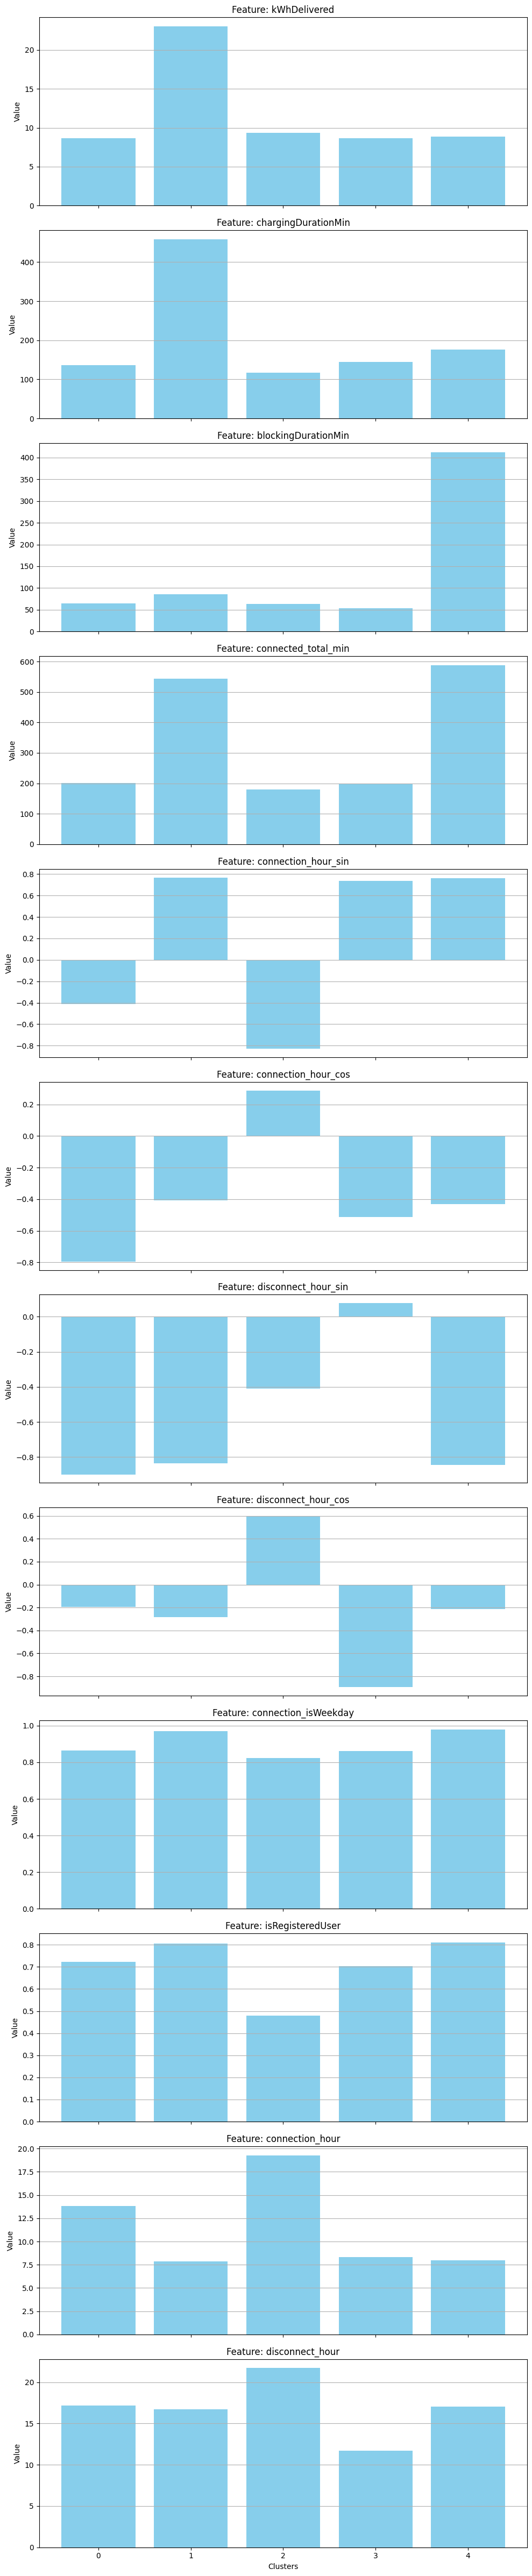

In [13]:
plot_cluster_centers(kmeans,features)